# Mobilité urbaine dans la région de Dakar : coût du déplacement et typologie des territoires

**Projet Spark — Big Data**

Ce notebook exploite les données de l'enquête ménages-déplacements fournies au format Excel (`donnees_deplacement_PSpark 2026.xlsx`). Après une étape de nettoyage, il développe deux volets complémentaires :

- **Partie A — Classification supervisée.** Prédire si un déplacement est **payant** ou **gratuit** à partir du profil de l'individu et des caractéristiques spatio-temporelles du déplacement, afin d'identifier les facteurs d'inégalité face au coût de la mobilité.
- **Partie B — Clustering non supervisé.** Construire une **typologie des strates** (zones de la région) à partir de leurs pratiques de mobilité.

Les traitements sont réalisés avec **PySpark** (Spark SQL et MLlib). Les statistiques descriptives sont **pondérées par `Poids_extra`** afin d'être représentatives de la population et non du seul échantillon.

## 0. Initialisation

In [ ]:
import os, sys, glob

jdk = glob.glob(r"C:\Program Files\Java\jdk-21*") + glob.glob(r"C:\Program Files\Eclipse Adoptium\jdk-21*")
if jdk:
    os.environ["JAVA_HOME"] = jdk[0]
    os.environ["PATH"] = os.path.join(jdk[0], "bin") + os.pathsep + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, StringType
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler, PCA
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator, RegressionEvaluator, ClusteringEvaluator
from pyspark.ml.clustering import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

spark = (SparkSession.builder.appName("MobiliteDakar").master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
sns.set_theme(style="whitegrid")

## 1. Chargement et nettoyage

### 1.1 Chargement

Spark ne lit pas nativement le format Excel. Les feuilles `deplacement` et `strate_commune` sont donc lues avec pandas, exportées en CSV, puis chargées dans Spark avec `spark.read.csv`. Tout le typage et le nettoyage sont ensuite réalisés dans Spark.

In [ ]:
PATH = "donnees_deplacement_PSpark 2026.xlsx"

def excel_vers_spark(feuille):
    pdf = pd.read_excel(PATH, sheet_name=feuille, dtype=str)
    pdf.columns = pdf.columns.str.strip()
    pdf.to_csv(f"{feuille}.csv", index=False)
    return spark.read.csv(f"{feuille}.csv", header=True)

raw = excel_vers_spark("deplacement")
strates = excel_vers_spark("strate_commune")
print(raw.count(), "déplacements,", len(raw.columns), "colonnes")

45605 déplacements, 33 colonnes


**Aperçu des données brutes.** Toutes les colonnes sont lues comme du texte (`string`) : le typage est fait volontairement à l'étape suivante. On remarque déjà les cases vides de `Mode2` à `Mode4` et le format `HHMM` des heures.

In [ ]:
apercu = ["numMena", "num_individu", "num_Deplacement", "HeureDepart", "HeureArrivee", "Duree (mn)",
           "Mode1", "Mode2", "Mode3", "Mode4", "Moyen de transport", "Cout", "Age", "Sexe"]
raw.select(*apercu).show(8, truncate=False)
raw.printSchema()

+-------+------------+---------------+-----------+------------+----------+-----------------------+-----+-----+-----+------------------+----+---+-----+
|numMena|num_individu|num_Deplacement|HeureDepart|HeureArrivee|Duree (mn)|Mode1                  |Mode2|Mode3|Mode4|Moyen de transport|Cout|Age|Sexe |
+-------+------------+---------------+-----------+------------+----------+-----------------------+-----+-----+-----+------------------+----+---+-----+
|1      |1           |1              |815        |820         |5         |Autre                  |NULL |NULL |NULL |Autre             |0   |53 |Homme|
|1      |1           |2              |2000       |2020        |20        |MobyletteMotoConducteur|NULL |NULL |NULL |Moto              |0   |53 |Homme|
|1      |2           |1              |610        |615         |5         |APied                  |NULL |NULL |NULL |APied             |0   |30 |Femme|
|1      |2           |2              |1130       |1135        |5         |APied               

### 1.2 Renommage et typage

In [ ]:
raw = (raw.withColumnRenamed("Duree (mn)", "Duree")
          .withColumnRenamed("Dextination_StrateArrivee", "Destination_StrateArrivee")
          .withColumnRenamed("Moyen de transport", "MoyenTransport"))

mode_cols = ["NbTrajetsAPied", "NbTrajetsAutre", "NbTrajetsMoto", "NbTrajetsVoiture", "NbTrajetsTaxi",
             "NbTrajetsClando", "NbTrajetsCarRapide", "NbTrajetsNN", "NbTrajetsDDD", "NbTrajetsTata"]
num_cols = ["Poids_extra", "Duree", "NbTrajets", "Cout", "Age"] + mode_cols
cat_cols = ["Sexe", "PositMenage", "Motif", "Origine_StrateDepart", "Destination_StrateArrivee",
            "Mode1", "Mode2", "Mode3", "Mode4", "MoyenTransport"]

for c in num_cols:
    raw = raw.withColumn(c, F.regexp_replace(F.trim(F.col(c)), ",", ".").cast("double"))
for c in cat_cols:
    raw = raw.withColumn(c, F.trim(F.regexp_replace(F.col(c), r"\.0$", "")))

In [ ]:
raw.select("Duree", "Cout", "Age", "Poids_extra", "NbTrajets", "Mode1", "Mode2").printSchema()
raw.select("Duree", "Cout", "Age", "Poids_extra", "NbTrajets", "Mode1", "Mode2").show(5)

root
 |-- Duree: double (nullable = true)
 |-- Cout: double (nullable = true)
 |-- Age: double (nullable = true)
 |-- Poids_extra: double (nullable = true)
 |-- NbTrajets: double (nullable = true)
 |-- Mode1: string (nullable = true)
 |-- Mode2: string (nullable = true)

+-----+----+----+----------------+---------+--------------------+-----+
|Duree|Cout| Age|     Poids_extra|NbTrajets|               Mode1|Mode2|
+-----+----+----+----------------+---------+--------------------+-----+
|  5.0| 0.0|53.0|122.133333333333|      1.0|               Autre| NULL|
| 20.0| 0.0|53.0|122.133333333333|      1.0|MobyletteMotoCond...| NULL|
|  5.0| 0.0|30.0|122.133333333333|      1.0|               APied| NULL|
|  5.0| 0.0|30.0|122.133333333333|      1.0|               APied| NULL|
|  5.0| 0.0|30.0|122.133333333333|      1.0|               APied| NULL|
+-----+----+----+----------------+---------+--------------------+-----+
only showing top 5 rows


### 1.3 Valeurs manquantes et doublons

In [ ]:
total = raw.count()
manquants = raw.select([F.round(F.sum(F.col(c).isNull().cast("int")) / total * 100, 2).alias(c) for c in raw.columns])
manquants.toPandas().T.rename(columns={0: "% manquant"}).query("`% manquant` > 0")

,% manquant
Mode2,82.94
Mode3,93.06
Mode4,99.16
Cout,0.02


In [ ]:
cle = ["numMena", "num_individu", "num_Deplacement"]
print("Doublons sur la clé :", total - raw.dropDuplicates(cle).count())
print("Ménages :", raw.select("numMena").distinct().count())
print("Individus :", raw.select("numMena", "num_individu").distinct().count())

Doublons sur la clé : 0
Ménages : 3127
Individus : 11457


**Bilan.** Le jeu de données est quasi complet et ne contient aucun doublon sur la clé (ménage, individu, déplacement). Les valeurs manquantes de `Mode2`, `Mode3` et `Mode4` sont **structurelles** : elles correspondent aux déplacements effectués avec un seul mode, ou avec moins de quatre trajets, et non à une perte d'information. Leur nombre est cohérent avec `NbTrajets`. Elles sont donc codées `"Aucun"` et non imputées. Les rares valeurs manquantes de `Cout` (quelques observations) sont supprimées.

### 1.4 Conversion des heures

Les heures de départ sont converties en **minutes depuis minuit** (`Dep_min`), une échelle numérique continue de 0 à 1 439 qui permet ensuite de découper la journée en périodes. Dans ce fichier, les heures sont codées en entier `HHMM` : `815` signifie 8h15, soit 8 × 60 + 15 = **495 minutes**.

**Pourquoi 1 440 ?** Une journée compte 24 × 60 = **1 440 minutes** : les minutes depuis minuit vont donc de 0 (00h00) à 1 439 (23h59). Or certains départs sont codés au-delà de 24h, car la journée d'enquête déborde après minuit : `2530` signifie 1h30 du matin le lendemain. Le calcul direct donnerait 25 × 60 + 30 = 1 530 minutes, valeur impossible sur une journée, et ce départ serait classé à tort en « Soirée ». Le **modulo 1 440** retire une journée entière : 1 530 − 1 440 = **90 minutes**, soit bien 01h30, classé en « Nuit ». Pour une heure normale (495 < 1 440), le modulo ne change rien.

La fonction gère aussi les autres formats qu'un export Excel peut produire (`HH:MM`, fraction de journée), afin que le code reste valable sur un autre fichier.

In [ ]:
def heure_en_minutes(col):
    h = F.trim(F.col(col))
    num = h.cast("double")
    hh = F.regexp_extract(h, r"(\d{1,2})[:hH](\d{2})", 1).cast("int")
    mm = F.regexp_extract(h, r"(\d{1,2})[:hH](\d{2})", 2).cast("int")
    minutes = (F.when(h.rlike(r"\d{1,2}[:hH]\d{2}"), hh * 60 + mm)
                .when(num < 1, F.round(num * 1440))
                .when(num <= 24, F.round(num * 60))
                .otherwise(F.floor(num / 100) * 60 + num % 100)
                .cast("int"))
    return F.pmod(minutes, F.lit(1440))

num_dep = F.col("HeureDepart").cast("double")
minutes_brutes = (F.floor(num_dep / 100) * 60 + num_dep % 100).cast("int")

print("Départs codés après minuit (>= 2400) :", raw.filter(num_dep >= 2400).count())
raw = (raw.withColumn("Dep_min", heure_en_minutes("HeureDepart"))
          .withColumn("Arr_min", heure_en_minutes("HeureArrivee"))
          .withColumn("Duree_calc", F.pmod(F.col("Arr_min") - F.col("Dep_min"), F.lit(1440))))

demo = (raw.select("HeureDepart", minutes_brutes.alias("minutes_avant_modulo"), "Dep_min")
           .dropDuplicates(["HeureDepart"]))
(demo.filter(F.col("HeureDepart").isin("615", "815", "1130", "1745", "2000"))
     .union(demo.filter(num_dep >= 2400).orderBy(num_dep).limit(4))
     .orderBy(F.col("HeureDepart").cast("int"))
     .withColumn("heure_lue", F.format_string("%02dh%02d", F.floor(F.col("Dep_min") / 60).cast("int"), (F.col("Dep_min") % 60).cast("int")))
     .show())
print("Heures non converties :", raw.filter(F.col("Dep_min").isNull()).count())

Départs codés après minuit (>= 2400) : 270
+-----------+--------------------+-------+---------+
|HeureDepart|minutes_avant_modulo|Dep_min|heure_lue|
+-----------+--------------------+-------+---------+
|        615|                 375|    375|    06h15|
|        815|                 495|    495|    08h15|
|       1130|                 690|    690|    11h30|
|       1745|                1065|   1065|    17h45|
|       2000|                1200|   1200|    20h00|
|       2400|                1440|      0|    00h00|
|       2401|                1441|      1|    00h01|
|       2405|                1445|      5|    00h05|
|       2406|                1446|      6|    00h06|
+-----------+--------------------+-------+---------+

Heures non converties : 0


### 1.5 Valeurs aberrantes et imputation

In [ ]:
age_min, age_max = raw.agg(F.min("Age"), F.max("Age")).first()
age_min = int(age_min)

print("Durée <= 0 ou > 300 min :", raw.filter((F.col("Duree") <= 0) | (F.col("Duree") > 300)).count())
print("Coût négatif :", raw.filter(F.col("Cout") < 0).count())
print("Coût codé 99999 (non renseigné) :", raw.filter(F.col("Cout") >= 99999).count())
print("Coût manquant :", raw.filter(F.col("Cout").isNull()).count())
print(f"Âge observé : de {age_min} à {int(age_max)} ans")
somme_modes = sum(F.coalesce(F.col(c), F.lit(0)) for c in mode_cols)
print("Somme par mode = NbTrajets :", raw.filter(F.abs(F.col("NbTrajets") - somme_modes) < 0.5).count())
ecart = F.col("NbTrajets") * F.col("Poids_extra") - somme_modes
print("Somme par mode != NbTrajets x Poids_extra :", raw.filter(F.abs(ecart) > 1).count())
print("  dont somme par mode inférieure (trajets non comptés) :", raw.filter(ecart > 1).count())
raw.select("Duree", "Cout", "Age").summary("min", "25%", "50%", "75%", "max").show()

Durée <= 0 ou > 300 min : 31
Coût négatif : 0
Coût codé 99999 (non renseigné) : 1
Coût manquant : 11
Âge observé : de 11 à 95 ans
Somme par mode = NbTrajets : 0
Somme par mode != NbTrajets x Poids_extra : 2780
  dont somme par mode inférieure (trajets non comptés) : 2780
+-------+-----+-------+----+
|summary|Duree|   Cout| Age|
+-------+-----+-------+----+
|    min|  1.0|    0.0|11.0|
|    25%|  5.0|    0.0|18.0|
|    50%| 10.0|    0.0|27.0|
|    75%| 23.0|    0.0|39.0|
|    max|900.0|99999.0|95.0|
+-------+-----+-------+----+



**Aperçu des observations problématiques (avant nettoyage).** On affiche les durées aberrantes, le coût codé `99999` et les coûts manquants. Pour les durées, on compare la durée déclarée à la durée **recalculée à partir des heures** (`Duree_calc` = arrivée − départ, modulo 1 440 pour les trajets qui passent minuit).

In [ ]:
vue = cle + ["HeureDepart", "HeureArrivee", "Duree", "Duree_calc", "MoyenTransport", "Cout", "Age"]

aberrants = raw.filter((F.col("Duree") <= 0) | (F.col("Duree") > 300))
print("Répartition des durées aberrantes :")
aberrants.groupBy("Duree").count().orderBy("Duree").show(50)
aberrants.select(*vue).orderBy("Duree").show(40, truncate=False)

print("Fiabilité de la durée recalculée sur les durées valides :")
valides = raw.filter(F.col("Duree").between(1, 300))
print(f"  écart <= 5 min dans {valides.filter(F.abs(F.col('Duree') - F.col('Duree_calc')) <= 5).count() / valides.count():.1%} des cas")

print("Coûts codés 99999 ou manquants :")
raw.filter(F.col("Cout").isNull() | (F.col("Cout") >= 99999)).select(*vue).show(truncate=False)

Répartition des durées aberrantes :
+-----+-----+
|Duree|count|
+-----+-----+
|310.0|    1|
|315.0|    1|
|320.0|    1|
|360.0|    1|
|363.0|    1|
|364.0|    1|
|390.0|    5|
|391.0|    1|
|393.0|    1|
|455.0|    1|
|464.0|    1|
|480.0|    3|
|483.0|    1|
|545.0|    1|
|550.0|    1|
|552.0|    3|
|570.0|    1|
|600.0|    1|
|750.0|    1|
|795.0|    1|
|810.0|    1|
|840.0|    1|
|900.0|    1|
+-----+-----+

+-------+------------+---------------+-----------+------------+-----+----------+--------------+-------+----+
|numMena|num_individu|num_Deplacement|HeureDepart|HeureArrivee|Duree|Duree_calc|MoyenTransport|Cout   |Age |
+-------+------------+---------------+-----------+------------+-----+----------+--------------+-------+----+
|503    |1           |2              |1800       |2310        |310.0|310       |Voiture       |0.0    |40.0|
|1641   |8           |1              |900        |1415        |315.0|315       |NN            |1300.0 |27.0|
|3988   |5           |2              |18

In [ ]:
mediane_mode = (raw.filter(F.col("Cout").isNotNull() & (F.col("Cout") < 99999))
                   .groupBy("MoyenTransport")
                   .agg(F.expr("percentile_approx(Cout, 0.5)").alias("Cout_median_mode")))

duree_ok = F.col("Duree").between(1, 300)
calc_ok = F.col("Duree_calc").between(1, 300)

clean = (raw
         .withColumn("Duree_brute", F.col("Duree"))
         .withColumn("Cout_brut", F.col("Cout"))
         .withColumn("Cout", F.when(F.col("Cout") >= 99999, None).otherwise(F.col("Cout")))
         .join(mediane_mode, "MoyenTransport", "left")
         .withColumn("Cout_impute", F.col("Cout").isNull() & F.col("Cout_median_mode").isNotNull())
         .withColumn("Cout", F.coalesce(F.col("Cout"), F.col("Cout_median_mode")))
         .withColumn("Duree_imputee", ~duree_ok & calc_ok)
         .withColumn("Duree", F.when(duree_ok, F.col("Duree")).when(calc_ok, F.col("Duree_calc")))
         .fillna(0, subset=mode_cols)
         .fillna("Aucun", subset=["Mode2", "Mode3", "Mode4"])
         .fillna("Inconnu", subset=["MoyenTransport"])
         .filter(F.col("Cout").isNotNull() & (F.col("Cout") >= 0))
         .filter(F.col("Duree").isNotNull())
         .filter(F.col("Age").isNotNull())
         .filter(F.col("Dep_min").isNotNull())
         .drop("Cout_median_mode"))

print("Durées imputées à partir des heures :", clean.filter("Duree_imputee").count())
print("Coûts imputés par la médiane du mode :", clean.filter("Cout_impute").count())

Durées imputées à partir des heures : 0
Coûts imputés par la médiane du mode : 12


**Aperçu des mêmes observations après nettoyage.** Pour chaque ligne problématique, on voit la valeur d'origine (`Duree_brute`, `Cout_brut`) et la valeur retenue. Une ligne absente de ce tableau a été supprimée faute de valeur fiable.

In [ ]:
cles_pb = (aberrants.select(*cle)
           .union(raw.filter(F.col("Cout").isNull() | (F.col("Cout") >= 99999)).select(*cle)))
(clean.join(cles_pb, cle)
      .select(*cle, "MoyenTransport", "Duree_brute", "Duree", "Duree_imputee", "Cout_brut", "Cout", "Cout_impute")
      .orderBy("Duree_brute").show(50, truncate=False))
print("Lignes problématiques :", cles_pb.count(), "| conservées après imputation :", clean.join(cles_pb, cle).count())

+-------+------------+---------------+--------------+-----------+-----+-------------+---------+----+-----------+
|numMena|num_individu|num_Deplacement|MoyenTransport|Duree_brute|Duree|Duree_imputee|Cout_brut|Cout|Cout_impute|
+-------+------------+---------------+--------------+-----------+-----+-------------+---------+----+-----------+
|8103   |8           |1              |Autre         |15.0       |15.0 |false        |NULL     |0.0 |true       |
|8105   |3           |1              |Autre         |15.0       |15.0 |false        |NULL     |0.0 |true       |
|8105   |6           |3              |Autre         |20.0       |20.0 |false        |NULL     |0.0 |true       |
|8103   |9           |1              |Autre         |30.0       |30.0 |false        |NULL     |0.0 |true       |
|8105   |4           |1              |Autre         |30.0       |30.0 |false        |NULL     |0.0 |true       |
|8105   |6           |1              |Autre         |30.0       |30.0 |false        |NULL     |0

**Imputation des modes : avant / après.** Les cases vides de `Mode2` à `Mode4` (manquants structurels) sont remplacées par `"Aucun"`.

In [ ]:
ex_modes = raw.filter(F.col("NbTrajets") <= 2).select(*cle).limit(4)
print("Avant :")
raw.join(ex_modes, cle).select(*cle, "NbTrajets", "Mode1", "Mode2", "Mode3", "Mode4").show(truncate=False)
print("Après :")
clean.join(ex_modes, cle).select(*cle, "NbTrajets", "Mode1", "Mode2", "Mode3", "Mode4").show(truncate=False)

Avant :
+-------+------------+---------------+---------+-----------------------+-----+-----+-----+
|numMena|num_individu|num_Deplacement|NbTrajets|Mode1                  |Mode2|Mode3|Mode4|
+-------+------------+---------------+---------+-----------------------+-----+-----+-----+
|1      |1           |1              |1.0      |Autre                  |NULL |NULL |NULL |
|1      |1           |2              |1.0      |MobyletteMotoConducteur|NULL |NULL |NULL |
|1      |2           |1              |1.0      |APied                  |NULL |NULL |NULL |
|1      |2           |2              |1.0      |APied                  |NULL |NULL |NULL |
+-------+------------+---------------+---------+-----------------------+-----+-----+-----+

Après :
+-------+------------+---------------+---------+-----------------------+-----+-----+-----+
|numMena|num_individu|num_Deplacement|NbTrajets|Mode1                  |Mode2|Mode3|Mode4|
+-------+------------+---------------+---------+-----------------------+-

**Bilan chiffré avant / après nettoyage.**

In [ ]:
def resume(d, etape):
    return d.select(F.lit(etape).alias("Étape"), F.count("*").alias("lignes"),
                    F.min("Duree").alias("durée min"), F.max("Duree").alias("durée max"),
                    F.max("Cout").alias("coût max"),
                    F.sum(F.col("Cout").isNull().cast("int")).alias("coût manquant"),
                    F.sum(F.col("Mode2").isNull().cast("int")).alias("Mode2 vide"),
                    F.min("Age").alias("âge min"), F.max("Age").alias("âge max"))

resume(raw, "Avant").union(resume(clean, "Après")).show()

+-----+------+---------+---------+--------+-------------+----------+-------+-------+
|Étape|lignes|durée min|durée max|coût max|coût manquant|Mode2 vide|âge min|âge max|
+-----+------+---------+---------+--------+-------------+----------+-------+-------+
|Avant| 45605|      1.0|    900.0| 99999.0|           11|     37824|   11.0|   95.0|
|Après| 45574|      1.0|    300.0| 20000.0|            0|         0|   11.0|   95.0|
+-----+------+---------+---------+--------+-------------+----------+-------+-------+



**Lecture.** Les anomalies sont d'abord **examinées**, puis corrigées quand c'est possible ; elles ne sont supprimées qu'en dernier recours.

- **Les 31 durées supérieures à 5 heures** (de 310 à 900 minutes) ne sont **pas des erreurs de saisie** : la durée recalculée à partir des heures de départ et d'arrivée leur est identique dans 100 % des cas (par exemple 18h00 → 23h10 = 310 min, 05h00 → 20h00 = 900 min). Aucune ne peut donc être « corrigée ». Ce sont des déplacements atypiques de 5 à 15 heures, souvent intermodaux et coûteux (jusqu'à 10 000 FCFA), qui relèvent de voyages longue distance et non de la mobilité urbaine quotidienne étudiée. Ils sont écartés (31 lignes, 0,07 %). Aucune durée nulle n'a été trouvée.
- **Les 12 coûts manquants ou codés `99999`** (code de non-réponse) sont **imputés par le coût médian du même moyen de transport**, au lieu d'être supprimés. Ce choix s'appuie sur la régression du coût (A.5), qui montre que le mode explique l'essentiel du prix ; la médiane est préférée à la moyenne car elle n'est pas tirée par les trajets très chers. Les 12 lignes concernées sont toutes de mode « Autre », dont le coût médian est 0 FCFA : elles sont donc imputées à 0. La colonne `Cout_impute` garde la trace de chaque imputation.
- **Âge** : aucune valeur aberrante. L'âge observé va de **11 à 95 ans** : l'enquête déplacements ne porte que sur les individus de 11 ans et plus. La première tranche d'âge part donc de **11 ans**, et non de 0.
- **Colonnes `NbTrajets*`** : elles sont **déjà multipliées par `Poids_extra`**. Aucune ligne ne vérifie `somme par mode = NbTrajets`, mais comparées à `NbTrajets × Poids_extra`, seules **2 780 lignes (6 %)** diffèrent, toujours parce que des trajets (essentiellement à pied) ne sont pas ventilés par mode. La Partie B n'en retient que l'information « mode utilisé ou non » (`NbTrajetsX > 0`), pour éviter une double pondération.

### 1.6 Rattachement des communes

La feuille `strate_commune` associe à chaque code de strate le nom de sa commune. Les codes absents de cette table sont regroupés sous l'étiquette `Hors zone`.

In [ ]:
communes = (strates.select(F.trim("code strate").alias("Strate"), F.trim("Communes").alias("Commune"))
                   .dropna()
                   .groupBy("Strate").agg(F.concat_ws(" / ", F.collect_list("Commune")).alias("Commune")))

clean = (clean
         .join(communes.withColumnRenamed("Strate", "Origine_StrateDepart")
                       .withColumnRenamed("Commune", "CommuneDepart"), "Origine_StrateDepart", "left")
         .join(communes.withColumnRenamed("Strate", "Destination_StrateArrivee")
                       .withColumnRenamed("Commune", "CommuneArrivee"), "Destination_StrateArrivee", "left")
         .fillna("Hors zone", subset=["CommuneDepart", "CommuneArrivee"]))

print(f"{total} déplacements initiaux -> {clean.count()} après nettoyage ({(1 - clean.count() / total):.2%} supprimés)")

45605 déplacements initiaux -> 45574 après nettoyage (0.07% supprimés)


**Bilan du nettoyage.** La base passe de **45 605** à **45 574** déplacements : seules les **31 durées hors champ (0,07 %)** sont supprimées, et les 12 coûts manquants ou codés `99999` sont imputés. Les 270 départs codés après minuit ont été ramenés sur 24 heures, et les cases vides de `Mode2` à `Mode4` remplacées par `"Aucun"`. Après nettoyage, il ne reste aucune valeur manquante. La base est typée et enrichie du nom des communes.

## 2. Construction des variables

À partir des données nettoyées, on construit :

- `Payant` : variable cible (1 si `Cout > 0`, 0 sinon) ;
- `PeriodeJour` : période de départ (pointe du matin 6h-9h, pointe du soir 16h-19h, etc.) ;
- `TrancheAge` : âge regroupé en classes, la première partant de l'**âge minimum observé** dans les données (et non de 0) ;
- `MemeStrate` : 1 si le déplacement reste dans la même strate (proxy d'un déplacement court) ;
- `NbModes` : nombre de modes utilisés au cours du déplacement (1 à 4).

In [ ]:
df = (clean
      .withColumn("Payant", (F.col("Cout") > 0).cast("int"))
      .withColumn("MemeStrate", (F.col("Origine_StrateDepart") == F.col("Destination_StrateArrivee")).cast("int"))
      .withColumn("PeriodeJour",
          F.when(F.col("Dep_min") < 360, "Nuit")
           .when(F.col("Dep_min") < 540, "PointeMatin")
           .when(F.col("Dep_min") < 720, "Matinee")
           .when(F.col("Dep_min") < 840, "Midi")
           .when(F.col("Dep_min") < 960, "ApresMidi")
           .when(F.col("Dep_min") < 1140, "PointeSoir")
           .otherwise("Soiree"))
      .withColumn("TrancheAge",
          F.when(F.col("Age") < 15, f"{age_min}-14")
           .when(F.col("Age") < 25, "15-24")
           .when(F.col("Age") < 35, "25-34")
           .when(F.col("Age") < 50, "35-49")
           .when(F.col("Age") < 65, "50-64")
           .otherwise("65+"))
      .withColumn("NbModes", sum((F.col(c) != "Aucun").cast("int") for c in ["Mode1", "Mode2", "Mode3", "Mode4"]))
      .cache())

df.select("Age", "TrancheAge", "Sexe", "Motif", "Origine_StrateDepart", "PeriodeJour", "MemeStrate", "Cout", "Payant").show(5)

+----+----------+-----+---------------+--------------------+-----------+----------+----+------+
| Age|TrancheAge| Sexe|          Motif|Origine_StrateDepart|PeriodeJour|MemeStrate|Cout|Payant|
+----+----------+-----+---------------+--------------------+-----------+----------+----+------+
|53.0|     50-64|Homme|TravailAmbulant|                 D01|PointeMatin|         0| 0.0|     0|
|53.0|     50-64|Homme| RetourDomicile|                 D05|     Soiree|         0| 0.0|     0|
|30.0|     25-34|Femme|TravailHabituel|                 D01|PointeMatin|         1| 0.0|     0|
|30.0|     25-34|Femme| RetourDomicile|                 D01|    Matinee|         1| 0.0|     0|
|30.0|     25-34|Femme|TravailHabituel|                 D01|     Soiree|         1| 0.0|     0|
+----+----------+-----+---------------+--------------------+-----------+----------+----+------+
only showing top 5 rows


In [ ]:
def taux_payant(data, col):
    return (data.groupBy(col)
                .agg(F.sum("Poids_extra").alias("poids"),
                     F.sum(F.col("Poids_extra") * F.col("Payant")).alias("poids_payant"),
                     F.count("*").alias("n"))
                .withColumn("taux_payant", F.round(F.col("poids_payant") / F.col("poids") * 100, 1))
                .select(col, "n", "taux_payant")
                .orderBy(col))

df.groupBy("Payant").count().show()
df.agg(F.round(F.sum(F.col("Poids_extra") * F.col("Payant")) / F.sum("Poids_extra") * 100, 1)
       .alias("taux_payant_pondere_%")).show()

+------+-----+
|Payant|count|
+------+-----+
|     1|10453|
|     0|35121|
+------+-----+

+---------------------+
|taux_payant_pondere_%|
+---------------------+
|                 23.8|
+---------------------+



**Lecture.** **23,8 %** des déplacements sont payants dans la population pondérée (10 453 contre 35 121 dans l'échantillon). La marche reste donc le mode dominant. Les classes sont déséquilibrées : environ un déplacement payant pour trois gratuits. Un modèle naïf qui prédirait toujours « gratuit » atteindrait déjà environ 76 % d'accuracy. L'évaluation reposera donc sur l'AUC, ainsi que sur le rappel et le F1-score **de la classe payante**.

---
# Partie A — Qui paie pour se déplacer ?

## A.1 Analyse descriptive

Avant toute modélisation, on mesure le taux de déplacements payants (pondéré) selon les principales caractéristiques des individus et des déplacements.

In [ ]:
for c in ["Sexe", "TrancheAge", "PositMenage", "Motif", "PeriodeJour", "MemeStrate"]:
    taux_payant(df, c).show(truncate=False)

+-----+-----+-----------+
|Sexe |n    |taux_payant|
+-----+-----+-----------+
|Femme|22458|24.6       |
|Homme|23116|23.1       |
+-----+-----+-----------+

+----------+-----+-----------+
|TrancheAge|n    |taux_payant|
+----------+-----+-----------+
|11-14     |5680 |5.9        |
|15-24     |13786|18.2       |
|25-34     |11125|28.6       |
|35-49     |9141 |31.4       |
|50-64     |4621 |34.7       |
|65+       |1221 |23.5       |
+----------+-----+-----------+

+-----------+-----+-----------+
|PositMenage|n    |taux_payant|
+-----------+-----+-----------+
|AutreParent|8115 |19.7       |
|ChefMenage |9440 |30.5       |
|Conjoint   |5022 |27.8       |
|FilsFille  |18952|21.2       |
|FrereSoeur |2504 |26.7       |
|PereMere   |154  |29.4       |
|SansLien   |1387 |20.0       |
+-----------+-----+-----------+

+------------------------+-----+-----------+
|Motif                   |n    |taux_payant|
+------------------------+-----+-----------+
|Accompagnement          |470  |16.0       |

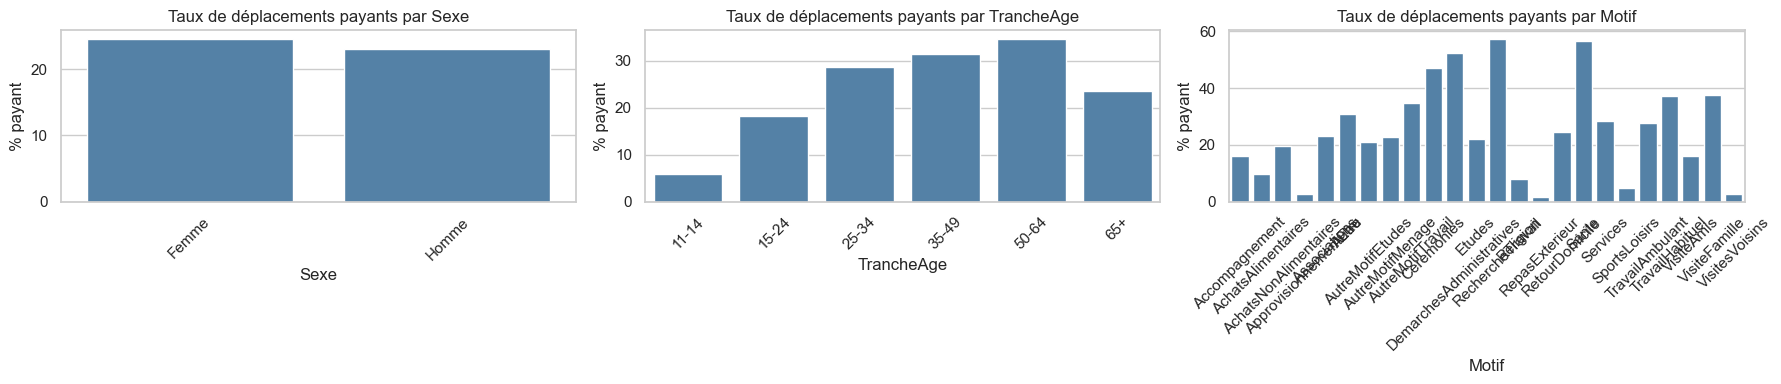

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, c in zip(axes, ["Sexe", "TrancheAge", "Motif"]):
    p = taux_payant(df, c).toPandas()
    sns.barplot(data=p, x=c, y="taux_payant", ax=ax, color="steelblue")
    ax.set_title(f"Taux de déplacements payants par {c}")
    ax.set_ylabel("% payant")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

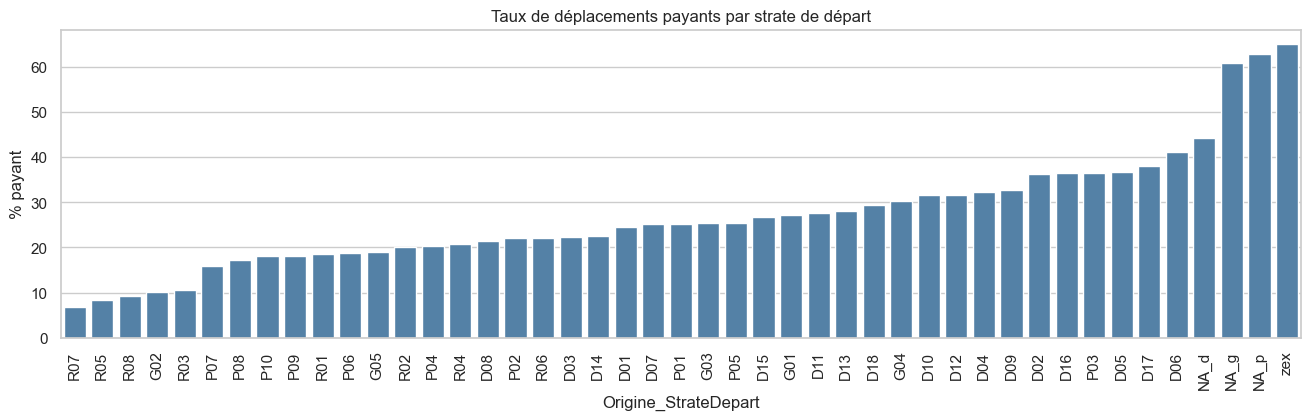

In [ ]:
strates_taux = taux_payant(df, "Origine_StrateDepart").filter("n >= 30").orderBy("taux_payant").toPandas()

plt.figure(figsize=(16, 4))
sns.barplot(data=strates_taux, x="Origine_StrateDepart", y="taux_payant", color="steelblue")
plt.xticks(rotation=90)
plt.title("Taux de déplacements payants par strate de départ")
plt.ylabel("% payant")
plt.show()

**Interprétation.**

- **Distance (`MemeStrate`)** : c'est l'écart le plus marqué. **61,2 %** des déplacements qui sortent de la strate sont payants, contre **6,5 %** des déplacements internes. Rester dans sa zone signifie, dans l'immense majorité des cas, se déplacer à pied.
- **Âge** : le taux croît régulièrement avec l'âge, de **5,9 %** chez les 11-14 ans (premier âge enquêté) à **34,7 %** chez les 50-64 ans, puis redescend à 23,5 % au-delà de 65 ans. Les déplacements des collégiens (école, proximité) sont presque tous à pied. Les actifs supportent l'essentiel du coût de la mobilité.
- **Position dans le ménage** : les chefs de ménage (**30,5 %**) et les conjoints (27,8 %) paient plus souvent que les enfants (21,2 %). Ce résultat est cohérent avec l'effet de l'âge et de l'activité.
- **Motif** : les motifs occasionnels et éloignés sont les plus souvent payants (recherche d'emploi 57,4 %, santé 56,6 %, démarches administratives 52,4 %, cérémonies 47,1 %). Les motifs de proximité sont presque toujours gratuits (repas à l'extérieur 1,7 %, approvisionnement en eau 2,6 %, loisirs 4,9 %, religion 8,0 %, achats alimentaires 9,6 %).
- **Période** : les heures de pointe concentrent les déplacements payants (32,3 % le matin, 28,1 % le soir), de même que les rares déplacements de nuit (30,3 %). La soirée est la période la moins coûteuse (16,9 %).
- **Sexe** : l'écart est faible et légèrement en faveur des femmes (**24,6 %** contre **23,1 %** pour les hommes). Le sexe n'apparaît donc pas comme un facteur discriminant du recours à un mode payant.

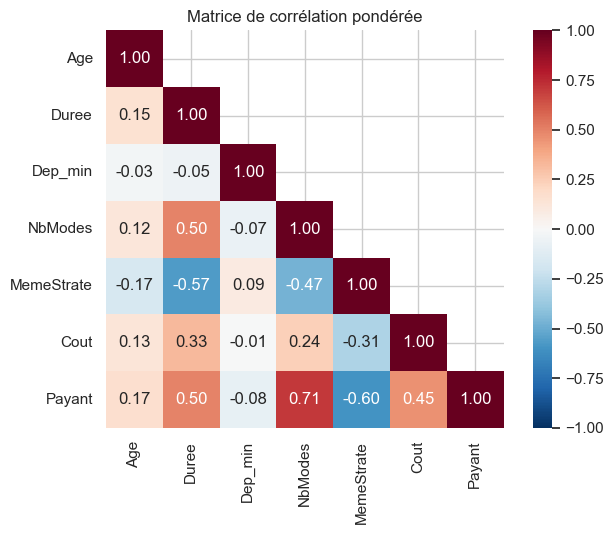

In [ ]:
# Matrice de corrélation pondérée
import numpy as np

vars_corr = ["Age", "Duree", "Dep_min", "NbModes", "MemeStrate", "Cout", "Payant"]
pdf = df.select(*vars_corr, "Poids_extra").toPandas()

# Corrélation de Pearson pondérée
cov = np.cov(pdf[vars_corr].values.T, aweights=pdf["Poids_extra"].values)
sd = np.sqrt(np.diag(cov))
corr = pd.DataFrame(cov / np.outer(sd, sd), index=vars_corr, columns=vars_corr)

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), square=True)
plt.title("Matrice de corrélation pondérée")
plt.tight_layout()
plt.show()

## A.2 Modélisation

**Choix des variables.** Pour éviter toute **fuite de données** (*data leakage*), toutes les variables qui décrivent directement le mode utilisé ou le coût sont exclues : `Mode1`–`Mode4`, `MoyenTransport`, `NbTrajets*` et `Cout`. La durée est également écartée, car elle dépend du mode choisi. Le modèle s'appuie uniquement sur :

| Type | Variables |
|---|---|
| Individu | `Age`, `Sexe`, `PositMenage` |
| Déplacement | `Motif`, `PeriodeJour` |
| Espace | `Origine_StrateDepart`, `Destination_StrateArrivee`, `MemeStrate` |

On compare deux modèles de MLlib : une **régression logistique** (modèle linéaire de référence) et une **forêt aléatoire** (modèle non linéaire). Les observations sont pondérées par `Poids_extra` (`weightCol`).

**Découpage apprentissage / test par ménage.** Les membres d'un même ménage se déplacent souvent ensemble et ont des déplacements très similaires. Un découpage ligne par ligne placerait des déplacements quasi identiques dans les deux échantillons et surestimerait les performances. Les **ménages** sont donc répartis en deux groupes (environ 80 % / 20 %) à partir d'un hachage de leur identifiant, ce qui rend le découpage reproductible : tous les déplacements d'un ménage se trouvent soit dans l'apprentissage, soit dans le test.

In [ ]:
cats = ["Sexe", "PositMenage", "Motif", "PeriodeJour", "Origine_StrateDepart", "Destination_StrateArrivee"]
nums = ["Age", "MemeStrate"]
idx = [c + "_idx" for c in cats]
ohe = [c + "_ohe" for c in cats]

indexer = StringIndexer(inputCols=cats, outputCols=idx, handleInvalid="keep")
encoder = OneHotEncoder(inputCols=idx, outputCols=ohe)
assembler_lr = VectorAssembler(inputCols=ohe + nums, outputCol="features")
assembler_rf = VectorAssembler(inputCols=idx + nums, outputCol="features")

lr = LogisticRegression(labelCol="Payant", featuresCol="features", weightCol="Poids_extra", maxIter=50)
rf = RandomForestClassifier(labelCol="Payant", featuresCol="features", weightCol="Poids_extra",
                            numTrees=100, maxDepth=8, maxBins=128, seed=42)

pipe_lr = Pipeline(stages=[indexer, encoder, assembler_lr, lr])
pipe_rf = Pipeline(stages=[indexer, assembler_rf, rf])

df = df.withColumn("Test", (F.abs(F.hash("numMena")) % 5 == 0).cast("int"))
train = df.filter("Test = 0").cache()
test = df.filter("Test = 1").cache()
print("Ménages :", train.select("numMena").distinct().count(), "/", test.select("numMena").distinct().count())
print("Déplacements :", train.count(), "/", test.count())

Ménages : 2481 / 645
Déplacements : 35895 / 9679


In [ ]:
model_lr = pipe_lr.fit(train)
model_rf = pipe_rf.fit(train)

pred_lr = model_lr.transform(test)
pred_rf = model_rf.transform(test)

indexer_mode = StringIndexer(inputCols=cats + ["MoyenTransport"], outputCols=idx + ["MoyenTransport_idx"], handleInvalid="keep")
assembler_mode = VectorAssembler(inputCols=idx + ["MoyenTransport_idx"] + nums + ["NbModes"], outputCol="features")
pred_rf_mode = Pipeline(stages=[indexer_mode, assembler_mode, rf]).fit(train).transform(test)

### A.3 Évaluation

In [ ]:
auc = BinaryClassificationEvaluator(labelCol="Payant", metricName="areaUnderROC")
def metric(name):
    return MulticlassClassificationEvaluator(labelCol="Payant", metricName=name)

resultats = []
for nom, pred in [("Régression logistique", pred_lr), ("Forêt aléatoire", pred_rf),
                  ("Forêt aléatoire + mode", pred_rf_mode)]:
    resultats.append({
        "Modèle": nom,
        "AUC": round(auc.evaluate(pred), 3),
        "Accuracy": round(metric("accuracy").evaluate(pred), 3),
        "Précision (payant)": round(metric("precisionByLabel").setMetricLabel(1.0).evaluate(pred), 3),
        "Rappel (payant)": round(metric("recallByLabel").setMetricLabel(1.0).evaluate(pred), 3),
        "F1 (payant)": round(metric("fMeasureByLabel").setMetricLabel(1.0).evaluate(pred), 3),
    })
pd.DataFrame(resultats)

,Modèle,AUC,Accuracy,Précision (payant),Rappel (payant),F1 (payant)
0,Régression logistique,0.870,0.839,0.656,0.668,0.662
1,Forêt aléatoire,0.879,0.848,0.662,0.730,0.694
2,Forêt aléatoire + mode,0.994,0.983,0.947,0.983,0.965


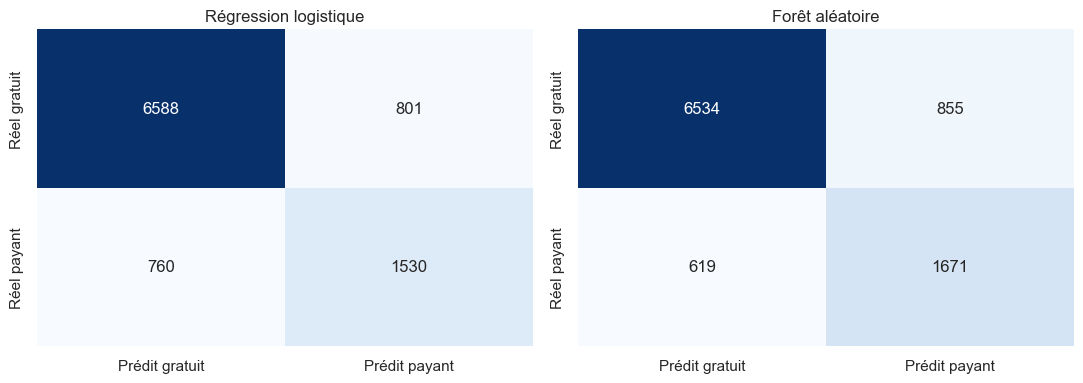

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (nom, pred) in zip(axes, [("Régression logistique", pred_lr), ("Forêt aléatoire", pred_rf)]):
    cm = pred.groupBy("Payant").pivot("prediction", [0.0, 1.0]).count().orderBy("Payant").toPandas()
    cm = cm.set_index("Payant").fillna(0).astype(int)
    cm.columns = ["Prédit gratuit", "Prédit payant"]
    cm.index = ["Réel gratuit", "Réel payant"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

**Interprétation.**

Les deux modèles sont performants, et le découpage par ménage garantit que ces scores ne sont pas gonflés par des déplacements quasi identiques entre apprentissage et test. La **forêt aléatoire** obtient les meilleurs résultats : **AUC = 0,879**, rappel = 0,730 et **F1 = 0,694** sur la classe payante. La régression logistique la suit de près (AUC = 0,870, F1 = 0,662).

L'AUC élevée et le F1 plus modeste ne se contredisent pas. Le modèle classe bien les déplacements selon leur probabilité d'être payants, mais au seuil de 0,5, environ un déplacement prédit payant sur trois est en réalité gratuit (précision = 0,66). Sur les 2 290 déplacements payants du jeu de test, la forêt aléatoire en identifie **1 671 (73 %)**, contre environ 1 530 pour la régression logistique.

**Avec ou sans le mode.** Lorsque `MoyenTransport` et `NbModes` sont ajoutés aux variables, l'AUC atteint **0,994** et le F1 **0,965** : connaître le mode revient presque à connaître la réponse. Cette comparaison justifie l'exclusion du mode ; sans elle, le modèle n'apprendrait rien d'utile sur les déterminants sociaux et spatiaux du recours à un mode payant.

### A.3 bis Analyse des erreurs : faux positifs et faux négatifs

On classe chaque déplacement du jeu de test selon la prédiction de la forêt aléatoire : **VP** (payant prédit payant), **VN** (gratuit prédit gratuit), **FP** (gratuit prédit payant) et **FN** (payant prédit gratuit). On compare ensuite leurs profils, y compris des variables que le modèle **n'a pas vues** (mode réel, durée, coût), pour comprendre pourquoi il s'est trompé.

In [ ]:
from pyspark.ml.functions import vector_to_array

analyse = (pred_rf
           .withColumn("proba_payant", F.round(vector_to_array("probability")[1], 3))
           .withColumn("Cas", F.when((F.col("Payant") == 1) & (F.col("prediction") == 1), "VP")
                               .when((F.col("Payant") == 0) & (F.col("prediction") == 0), "VN")
                               .when((F.col("Payant") == 0) & (F.col("prediction") == 1), "FP")
                               .otherwise("FN"))
           .cache())

(analyse.groupBy("Cas")
        .agg(F.count("*").alias("n"),
             F.round(F.avg("MemeStrate") * 100, 1).alias("% même strate"),
             F.round(F.avg("Age"), 1).alias("âge moyen"),
             F.round(F.avg("Duree"), 1).alias("durée moy (min)"),
             F.round(F.avg("Cout")).alias("coût moy (FCFA)"),
             F.round(F.avg("proba_payant"), 2).alias("proba moyenne"))
        .orderBy("Cas").show())

+---+----+-------------+---------+---------------+---------------+-------------+
|Cas|   n|% même strate|âge moyen|durée moy (min)|coût moy (FCFA)|proba moyenne|
+---+----+-------------+---------+---------------+---------------+-------------+
| FN| 619|         69.6|     30.4|           26.3|          230.0|         0.18|
| FP| 855|          0.0|     37.7|           28.0|            0.0|         0.61|
| VN|6534|         93.6|     27.4|           10.6|            0.0|         0.08|
| VP|1671|          0.0|     35.6|           42.5|          361.0|         0.65|
+---+----+-------------+---------+---------------+---------------+-------------+



In [ ]:
for cas in ["FN", "FP"]:
    print(f"Moyens de transport réels des {cas} :")
    (analyse.filter(F.col("Cas") == cas).groupBy("MoyenTransport").count()
            .withColumn("%", F.round(F.col("count") / F.sum("count").over(Window.partitionBy()) * 100, 1))
            .orderBy(F.desc("count")).show(6))

Moyens de transport réels des FN :
+--------------+-----+----+
|MoyenTransport|count|   %|
+--------------+-----+----+
|          Tata|  185|29.9|
|        Clando|  171|27.6|
|     CarRapide|  116|18.7|
|          Taxi|   61| 9.9|
|    Intermodal|   29| 4.7|
|            NN|   19| 3.1|
+--------------+-----+----+
only showing top 6 rows
Moyens de transport réels des FP :
+--------------+-----+----+
|MoyenTransport|count|   %|
+--------------+-----+----+
|         APied|  396|46.3|
|       Voiture|  281|32.9|
|          Moto|   65| 7.6|
|         Autre|   37| 4.3|
|        Clando|   25| 2.9|
|          Tata|   20| 2.3|
+--------------+-----+----+
only showing top 6 rows


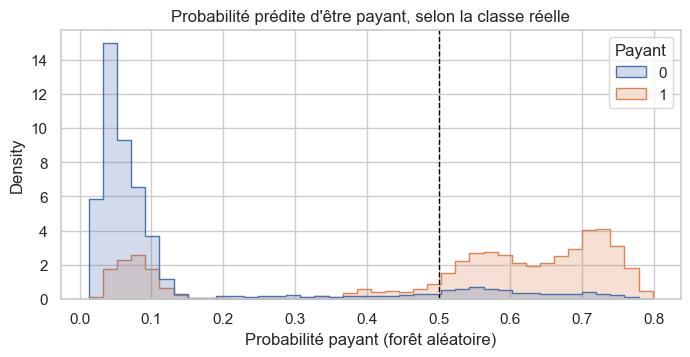

In [ ]:
pdf_proba = analyse.select("Payant", "proba_payant").toPandas()
plt.figure(figsize=(8, 3.5))
sns.histplot(data=pdf_proba, x="proba_payant", hue="Payant", bins=40, element="step", stat="density", common_norm=False)
plt.axvline(0.5, color="black", linestyle="--", linewidth=1)
plt.title("Probabilité prédite d'être payant, selon la classe réelle")
plt.xlabel("Probabilité payant (forêt aléatoire)")
plt.show()

**Un faux négatif et un faux positif tirés au hasard.** Pour chacun, on affiche ce que le modèle a vu, ce qu'il n'a pas vu (mode, durée, coût), puis le taux de déplacements payants observé dans l'apprentissage pour les déplacements **de même profil** (même `MemeStrate` et même motif). Ce taux explique la décision du modèle.

In [ ]:
vus = ["Age", "Sexe", "PositMenage", "Motif", "PeriodeJour", "Origine_StrateDepart", "Destination_StrateArrivee", "MemeStrate"]
caches = ["MoyenTransport", "Mode1", "Mode2", "Duree", "Cout"]

def expliquer(cas, graine):
    ligne = analyse.filter(F.col("Cas") == cas).orderBy(F.rand(graine)).first()
    print(f"===== {cas} tiré au hasard =====")
    print("Vu par le modèle   :", {c: ligne[c] for c in vus})
    print("Non vu par le modèle:", {c: ligne[c] for c in caches})
    print(f"Probabilité payant prédite : {ligne['proba_payant']:.1%}  ->  prédit {'PAYANT' if ligne['prediction'] == 1 else 'GRATUIT'}, réel {'PAYANT' if ligne['Payant'] == 1 else 'GRATUIT'}")
    semblables = train.filter((F.col("MemeStrate") == ligne["MemeStrate"]) & (F.col("Motif") == ligne["Motif"]))
    t = semblables.agg((F.sum(F.col("Poids_extra") * F.col("Payant")) / F.sum("Poids_extra")).alias("taux"),
                       F.count("*").alias("n")).first()
    print(f"Déplacements d'apprentissage de même profil (MemeStrate={ligne['MemeStrate']}, Motif={ligne['Motif']}) : "
          f"{t['n']}, dont {t['taux']:.1%} payants\n")

expliquer("FN", 42)
expliquer("FP", 42)

===== FN tiré au hasard =====
Vu par le modèle   : {'Age': 30.0, 'Sexe': 'Femme', 'PositMenage': 'FrereSoeur', 'Motif': 'RetourDomicile', 'PeriodeJour': 'Matinee', 'Origine_StrateDepart': 'P09', 'Destination_StrateArrivee': 'P09', 'MemeStrate': 1}
Non vu par le modèle: {'MoyenTransport': 'Clando', 'Mode1': 'TaxiClando', 'Mode2': 'Aucun', 'Duree': 30.0, 'Cout': 100.0}
Probabilité payant prédite : 10.9%  ->  prédit GRATUIT, réel PAYANT
Déplacements d'apprentissage de même profil (MemeStrate=1, Motif=RetourDomicile) : 10804, dont 6.9% payants

===== FP tiré au hasard =====
Vu par le modèle   : {'Age': 28.0, 'Sexe': 'Homme', 'PositMenage': 'AutreParent', 'Motif': 'RetourDomicile', 'PeriodeJour': 'Soiree', 'Origine_StrateDepart': 'R04', 'Destination_StrateArrivee': 'R03', 'MemeStrate': 0}
Non vu par le modèle: {'MoyenTransport': 'Voiture', 'Mode1': 'APied', 'Mode2': 'Voiture particuliere passager', 'Duree': 70.0, 'Cout': 0.0}
Probabilité payant prédite : 54.8%  ->  prédit PAYANT, réel GRATU

In [ ]:
cols_ex = vus + ["MoyenTransport", "Duree", "Cout", "proba_payant"]
print("Cinq autres faux négatifs :")
analyse.filter("Cas = 'FN'").orderBy(F.rand(7)).select(*cols_ex).show(5, truncate=False)
print("Cinq autres faux positifs :")
analyse.filter("Cas = 'FP'").orderBy(F.rand(7)).select(*cols_ex).show(5, truncate=False)

Cinq autres faux négatifs :
+----+-----+-----------+--------------+-----------+--------------------+-------------------------+----------+--------------+-----+-----+------------+
|Age |Sexe |PositMenage|Motif         |PeriodeJour|Origine_StrateDepart|Destination_StrateArrivee|MemeStrate|MoyenTransport|Duree|Cout |proba_payant|
+----+-----+-----------+--------------+-----------+--------------------+-------------------------+----------+--------------+-----+-----+------------+
|20.0|Femme|FrereSoeur |RetourDomicile|ApresMidi  |P09                 |P09                      |1         |Tata          |25.0 |200.0|0.078       |
|12.0|Homme|FilsFille  |Etudes        |PointeMatin|R02                 |R02                      |1         |Tata          |25.0 |150.0|0.061       |
|32.0|Homme|ChefMenage |RetourDomicile|Soiree     |D13                 |D13                      |1         |Intermodal    |30.0 |200.0|0.066       |
|18.0|Femme|FilsFille  |RetourDomicile|Midi       |D13                 |

**Interprétation des erreurs.**

Le tableau des profils montre que le modèle a appris une règle simple : **il ne prédit « payant » que pour les déplacements qui sortent de leur strate** (0 % de déplacements internes parmi les VP et les FP). Les erreurs sont les exceptions à cette règle.

- **Les 619 faux négatifs** sont des déplacements payants courts, majoritairement **internes à une strate** (69,6 %), faits en **Tata, clando ou car rapide** (76 % à eux trois), pour 230 FCFA en moyenne. La probabilité prédite est très basse (0,18 en moyenne) : rien dans le profil ne distingue ces déplacements d'un trajet à pied.
- **Les 855 faux positifs** sont tous des déplacements **entre deux strates** qui n'ont rien coûté : à **pied** entre strates voisines (46 %), ou en **voiture ou moto particulière** (41 %), qui n'impliquent pas de tarif payé. La variable `Payant` mesure un tarif acquitté, pas la motorisation : un passager de voiture ne paie rien, alors qu'il se déplace loin.

**Le faux négatif tiré au hasard** est une femme de 30 ans qui rentre chez elle en matinée, à l'intérieur de Keur Massar (P09 → P09), en clando pour 100 FCFA. Le modèle lui donne 10,9 % de chances de payer, et il a raison en moyenne : parmi les 10 804 déplacements d'apprentissage de même profil (même strate, retour au domicile), **seuls 6,9 % sont payants**. Le modèle suit le comportement dominant ; ce trajet en clando est une exception qu'il ne peut pas voir sans le mode.

**Le faux positif tiré au hasard** est un homme de 28 ans qui rentre chez lui en soirée de Rufisque Est à Rufisque Nord (R04 → R03), à pied puis en voiture comme passager, pour 0 FCFA. Le modèle lui donne 54,8 % de chances de payer, car **62,4 %** des 4 770 déplacements semblables (changement de strate, retour au domicile) sont payants.

**Conclusion.** Les erreurs ne sont pas aléatoires : elles correspondent aux deux cas que la distance seule ne permet pas de trancher, les courts trajets payants en transport informel et les longs trajets gratuits en véhicule particulier. Ajouter une variable de **possession d'un véhicule** par le ménage permettrait de réduire les faux positifs.

### A.4 Importance des variables

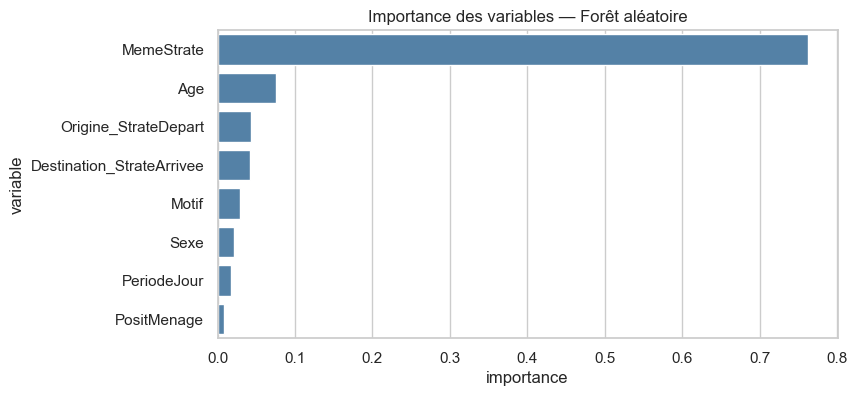

,variable,importance
7,MemeStrate,0.762217
6,Age,0.076034
4,Origine_StrateDepart,0.043323
5,Destination_StrateArrivee,0.042311
2,Motif,0.029565
0,Sexe,0.020770
3,PeriodeJour,0.017243
1,PositMenage,0.008537


In [ ]:
importances = pd.DataFrame({
    "variable": cats + nums,
    "importance": model_rf.stages[-1].featureImportances.toArray()
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(data=importances, x="importance", y="variable", color="steelblue")
plt.title("Importance des variables — Forêt aléatoire")
plt.show()
importances

**Interprétation.**

La variable **`MemeStrate`** domine très largement (importance = **0,76**). Viennent ensuite l'**âge** (0,08) puis les strates d'origine et de destination (0,04 chacune). Le motif, le sexe, la période et la position dans le ménage ont une contribution marginale (0,03 ou moins).

Le recours à un mode payant est donc avant tout une question de **distance** : sortir de sa strate implique presque toujours de payer un transport. Les caractéristiques individuelles jouent un rôle secondaire, l'âge étant la seule à peser réellement. L'analyse des erreurs (A.3 bis) confirme que le modèle repose presque entièrement sur cette variable.

## A.5 Régression du coût des déplacements payants

Le modèle précédent prédit **si** un déplacement est payant. On cherche maintenant à prédire **combien** il coûte. L'analyse porte sur les seuls déplacements payants. La cible est le logarithme du coût, `log(1 + Cout)`, car la distribution des coûts est très asymétrique.

Deux jeux de variables sont comparés :

- **sans mode** : profil de l'individu, espace, période et durée du déplacement (la durée est ici un proxy de la distance) ;
- **avec mode** : les mêmes variables, plus `MoyenTransport` et `NbModes`.

Le découpage par ménage et la pondération sont identiques à ceux de la classification. Les performances sont mesurées par le **R²** (sur l'échelle logarithmique) et l'**erreur absolue moyenne (MAE) en FCFA**.

In [ ]:
payants = df.filter("Payant = 1").withColumn("log_cout", F.log1p("Cout"))
train_c = payants.filter("Test = 0").cache()
test_c = payants.filter("Test = 1").cache()

(payants.groupBy("MoyenTransport")
        .agg(F.count("*").alias("n"),
             F.round(F.sum(F.col("Poids_extra") * F.col("Cout")) / F.sum("Poids_extra")).alias("cout_moyen"),
             F.round(F.expr("percentile_approx(Cout, 0.5)")).alias("cout_median"))
        .orderBy(F.desc("n")).show(truncate=False))

+--------------+----+----------+-----------+
|MoyenTransport|n   |cout_moyen|cout_median|
+--------------+----+----------+-----------+
|Tata          |3737|183.0     |150.0      |
|CarRapide     |1813|91.0      |100.0      |
|Clando        |1375|188.0     |100.0      |
|Intermodal    |1171|437.0     |300.0      |
|Taxi          |1079|1437.0    |1300.0     |
|DDD           |540 |169.0     |150.0      |
|NN            |485 |189.0     |150.0      |
|Autre         |172 |311.0     |150.0      |
|Voiture       |56  |1293.0    |500.0      |
|Moto          |25  |820.0     |1000.0     |
+--------------+----+----------+-----------+



In [ ]:
def modele_cout(cats_c, nums_c, algo):
    idx_c = [c + "_idx" for c in cats_c]
    etapes = [StringIndexer(inputCols=cats_c, outputCols=idx_c, handleInvalid="keep")]
    if algo == "lr":
        ohe_c = [c + "_ohe" for c in cats_c]
        etapes += [OneHotEncoder(inputCols=idx_c, outputCols=ohe_c),
                   VectorAssembler(inputCols=ohe_c + nums_c, outputCol="features"),
                   LinearRegression(labelCol="log_cout", weightCol="Poids_extra")]
    else:
        etapes += [VectorAssembler(inputCols=idx_c + nums_c, outputCol="features"),
                   RandomForestRegressor(labelCol="log_cout", weightCol="Poids_extra",
                                         numTrees=100, maxDepth=8, maxBins=128, seed=42)]
    pred = Pipeline(stages=etapes).fit(train_c).transform(test_c)
    return pred.withColumn("cout_predit", F.expm1("prediction"))

cats_sans = cats
nums_sans = nums + ["Duree"]
cats_avec = cats + ["MoyenTransport"]
nums_avec = nums_sans + ["NbModes"]

r2 = RegressionEvaluator(labelCol="log_cout", predictionCol="prediction", metricName="r2")
mae = RegressionEvaluator(labelCol="Cout", predictionCol="cout_predit", metricName="mae")

mediane = train_c.approxQuantile("Cout", [0.5], 0.001)[0]
mae_ref = test_c.select(F.avg(F.abs(F.col("Cout") - mediane))).first()[0]

preds_cout = {}
res_cout = [{"Modèle": "Référence (coût médian)", "Variables": "-", "R² (log)": 0.0, "MAE (FCFA)": round(mae_ref)}]
for algo, nom in [("lr", "Régression linéaire"), ("rf", "Forêt aléatoire")]:
    for variables, cc, nn in [("sans mode", cats_sans, nums_sans), ("avec mode", cats_avec, nums_avec)]:
        p = modele_cout(cc, nn, algo)
        preds_cout[(algo, variables)] = p
        res_cout.append({"Modèle": nom, "Variables": variables,
                         "R² (log)": round(r2.evaluate(p), 3), "MAE (FCFA)": round(mae.evaluate(p))})
pd.DataFrame(res_cout)

,Modèle,Variables,R² (log),MAE (FCFA)
0,Référence (coût médian),-,0.000,218
1,Régression linéaire,sans mode,0.149,218
2,Régression linéaire,avec mode,0.768,114
3,Forêt aléatoire,sans mode,0.201,209
4,Forêt aléatoire,avec mode,0.784,106


**Cas réels du jeu de validation.** On tire au hasard des déplacements payants du jeu de test et on compare leur coût réel aux prédictions de la forêt aléatoire, sans puis avec le mode. Le second tableau donne l'erreur moyenne par moyen de transport.

In [ ]:
sans = preds_cout[("rf", "sans mode")].select(*cle, "MoyenTransport", "Duree", "MemeStrate", "Cout",
                                              F.round("cout_predit").alias("predit_sans_mode"))
avec = preds_cout[("rf", "avec mode")].select(*cle, F.round("cout_predit").alias("predit_avec_mode"))
validation = sans.join(avec, cle).cache()

(validation.orderBy(F.rand(3))
           .select("MoyenTransport", "Duree", "MemeStrate", "Cout", "predit_sans_mode", "predit_avec_mode")
           .show(10))

(validation.groupBy("MoyenTransport")
           .agg(F.count("*").alias("n"),
                F.round(F.expr("percentile_approx(Cout, 0.5)")).alias("cout_median_reel"),
                F.round(F.avg(F.abs(F.col("Cout") - F.col("predit_sans_mode")))).alias("erreur_sans_mode"),
                F.round(F.avg(F.abs(F.col("Cout") - F.col("predit_avec_mode")))).alias("erreur_avec_mode"))
           .orderBy(F.desc("n")).show())

+--------------+-----+----------+------+----------------+----------------+
|MoyenTransport|Duree|MemeStrate|  Cout|predit_sans_mode|predit_avec_mode|
+--------------+-----+----------+------+----------------+----------------+
|          Tata| 30.0|         0| 200.0|           225.0|           160.0|
|          Tata| 60.0|         0| 150.0|           271.0|           209.0|
|          Taxi| 20.0|         1| 900.0|           222.0|           969.0|
|        Clando| 50.0|         0| 100.0|           233.0|           215.0|
|          Tata| 10.0|         0| 150.0|           151.0|           137.0|
|          Taxi| 45.0|         0|1300.0|           196.0|          1334.0|
|          Tata| 25.0|         0| 100.0|           167.0|           148.0|
|        Clando| 25.0|         1| 150.0|           122.0|           130.0|
|          Tata|120.0|         0| 500.0|           462.0|           288.0|
|          Tata| 50.0|         0| 250.0|           212.0|           221.0|
+--------------+-----+---

**Interprétation.**

Le coût d'un déplacement payant dépend d'abord du **mode** :
- les modes collectifs sont bon marché, avec un coût médian de 100 à 150 FCFA (car rapide, Tata, DDD, Ndiaga Ndiaye, clando) ;
- les déplacements intermodaux coûtent environ 300 FCFA ;
- le taxi coûte de loin le plus cher (1 300 FCFA en médiane, soit plus de dix fois un car rapide).

La comparaison des modèles le confirme :
- **Sans le mode**, les modèles n'expliquent qu'une faible part de la variance du coût : R² = 0,15 pour la régression linéaire et **0,20** pour la forêt aléatoire. L'erreur moyenne de la forêt aléatoire (209 FCFA) est à peine inférieure à celle de la référence qui prédit toujours le coût médian (218 FCFA).
- **Avec le mode**, le R² atteint **0,78** et l'erreur moyenne est divisée par deux (**106 FCFA**).

**Les cas réels du jeu de validation** rendent ce résultat concret. Un trajet en taxi de 45 minutes coûte 1 300 FCFA : le modèle sans mode prédit 196 FCFA, le modèle avec mode 1 334 FCFA. Sans le mode, le modèle prédit un coût « moyen » d'environ 200 FCFA pour tout le monde. L'erreur par moyen de transport le montre : sans le mode, elle atteint 1 057 FCFA en moyenne pour les taxis, contre 423 FCFA avec le mode ; pour le car rapide, elle passe de 91 à 27 FCFA.

Il existe donc deux niveaux de décision. Le fait de payer dépend surtout de la distance, c'est-à-dire du fait de sortir ou non de sa strate. Le montant payé dépend surtout du **choix du mode**, en particulier du recours au taxi plutôt qu'au transport collectif.

# Prédiction manuelle : saisir un déplacement et savoir s'il est payant ou non


**Cas réels du jeu de validation.** Avant la saisie manuelle, on vérifie le modèle sur des déplacements réels du jeu de test, jamais vus pendant l'apprentissage : profil, prédiction, probabilité et réalité.

In [ ]:
(analyse.orderBy(F.rand(11))
         .select("Age", "Sexe", "Motif", "PeriodeJour", "Origine_StrateDepart", "Destination_StrateArrivee",
                 "MemeStrate", "proba_payant", "prediction", "Payant", "Cas", "MoyenTransport")
         .show(8, truncate=False))

+----+-----+--------------+-----------+--------------------+-------------------------+----------+------------+----------+------+---+--------------+
|Age |Sexe |Motif         |PeriodeJour|Origine_StrateDepart|Destination_StrateArrivee|MemeStrate|proba_payant|prediction|Payant|Cas|MoyenTransport|
+----+-----+--------------+-----------+--------------------+-------------------------+----------+------------+----------+------+---+--------------+
|11.0|Femme|RetourDomicile|PointeMatin|R04                 |R04                      |1         |0.065       |0.0       |0     |VN |APied         |
|37.0|Femme|RetourDomicile|PointeSoir |R05                 |R05                      |1         |0.069       |0.0       |0     |VN |APied         |
|30.0|Homme|Etudes        |ApresMidi  |D06                 |D06                      |1         |0.041       |0.0       |0     |VN |APied         |
|20.0|Homme|RetourDomicile|PointeSoir |R04                 |R08                      |0         |0.573       |1.

In [ ]:
for c in ["Sexe", "PositMenage", "Motif"]:
    vals = sorted([r[0] for r in df.select(c).distinct().collect() if r[0] is not None])
    print(f"{c} possibles : {vals}")

sexe       = input("Sexe : ").strip()
age        = float(input("Âge : "))
posit      = input("PositMenage : ").strip()
motif      = input("Motif : ").strip()
strate_dep = input("Strate de départ : ").strip()
strate_arr = input("Strate d'arrivée : ").strip()
heure      = input("Heure de départ (HH:MM, ex 08:30) : ").strip()

hh, mm = heure.replace("h", ":").replace("H", ":").split(":")
dep_min = (int(hh) * 60 + int(mm)) % 1440

if   dep_min < 360:  periode = "Nuit"
elif dep_min < 540:  periode = "PointeMatin"
elif dep_min < 720:  periode = "Matinee"
elif dep_min < 840:  periode = "Midi"
elif dep_min < 960:  periode = "ApresMidi"
elif dep_min < 1140: periode = "PointeSoir"
else:                periode = "Soiree"

meme_strate = 1 if strate_dep == strate_arr else 0

nouveau = spark.range(1).select(
    F.lit(sexe).alias("Sexe"),
    F.lit(posit).alias("PositMenage"),
    F.lit(motif).alias("Motif"),
    F.lit(periode).alias("PeriodeJour"),
    F.lit(strate_dep).alias("Origine_StrateDepart"),
    F.lit(strate_arr).alias("Destination_StrateArrivee"),
    F.lit(age).cast("double").alias("Age"),
    F.lit(meme_strate).cast("int").alias("MemeStrate"),
)

print("\n--- Résultat ---")
print(f"Période : {periode} | Même strate : {'oui' if meme_strate else 'non'}")
for nom, modele in [("Régression logistique", model_lr), ("Forêt aléatoire", model_rf)]:
    r = modele.transform(nouveau).select("prediction", "probability").first()
    proba_payant = float(r["probability"][1])
    verdict = "PAYANT" if r["prediction"] == 1.0 else "GRATUIT"
    print(f"{nom:<22} → {verdict}  (probabilité payant = {proba_payant:.1%})")

Sexe possibles : ['Femme', 'Homme']
PositMenage possibles : ['AutreParent', 'ChefMenage', 'Conjoint', 'FilsFille', 'FrereSoeur', 'PereMere', 'SansLien']
Motif possibles : ['Accompagnement', 'AchatsAlimentaires', 'AchatsNonAlimentaires', 'ApprovisionnementEau', 'Associations', 'Autre', 'AutreMotifEtudes', 'AutreMotifMenage', 'AutreMotifTravail', 'Ceremonies', 'DemarchesAdministratives', 'Etudes', 'RechercheTravail', 'Religion', 'RepasExterieur', 'RetourDomicile', 'Sante', 'Services', 'SportsLoisirs', 'TravailAmbulant', 'TravailHabituel', 'VisiteAmis', 'VisiteFamille', 'VisitesVoisins']

--- Résultat ---
Période : Matinee | Même strate : non
Régression logistique  → PAYANT  (probabilité payant = 66.7%)
Forêt aléatoire        → PAYANT  (probabilité payant = 70.7%)


---
# Partie B — Typologie des strates

## B.1 Construction du profil de mobilité de chaque strate

Les 45 000 déplacements sont agrégés par strate de départ avec Spark. Chaque strate est décrite par :

| Indicateur | Définition |
|---|---|
| `part_marche`, `part_collectif`, `part_taxi`, `part_individuel` | Part des déplacements utilisant au moins une fois chaque famille de modes (collectif = car rapide, Ndiaga Ndiaye, DDD, Tata ; taxi = taxi + clando ; individuel = voiture + moto) |
| `duree_moy` | Durée moyenne d'un déplacement (min) |
| `cout_moy` | Coût moyen d'un déplacement (FCFA) |
| `part_intra` | Part des déplacements restant dans la strate |

Les codes situés hors de la région d'étude (`Hors zone`) et les strates comptant moins de 30 déplacements sont exclus.

In [ ]:
w = F.col("Poids_extra")

def part(*cols):
    utilise = (sum(F.col(c) for c in cols) > 0).cast("int")
    return F.sum(w * utilise) / F.sum(w)

profil = (df.groupBy(F.col("Origine_StrateDepart").alias("Strate"))
            .agg(F.count("*").alias("n"),
                 part("NbTrajetsAPied").alias("part_marche"),
                 part("NbTrajetsCarRapide", "NbTrajetsNN", "NbTrajetsDDD", "NbTrajetsTata").alias("part_collectif"),
                 part("NbTrajetsTaxi", "NbTrajetsClando").alias("part_taxi"),
                 part("NbTrajetsVoiture", "NbTrajetsMoto").alias("part_individuel"),
                 (F.sum(w * F.col("Duree")) / F.sum(w)).alias("duree_moy"),
                 (F.sum(w * F.col("Cout")) / F.sum(w)).alias("cout_moy"),
                 (F.sum(w * F.col("MemeStrate")) / F.sum(w)).alias("part_intra")))

communes = df.groupBy(F.col("Origine_StrateDepart").alias("Strate")).agg(F.first("CommuneDepart").alias("Commune"))

profil = (profil.join(communes, "Strate", "left")
                .filter((F.col("Commune") != "Hors zone") & (F.col("n") >= 30))
                .cache())

print(profil.count(), "strates retenues")
profil.select("Strate", "Commune", "n", *[F.round(c, 2).alias(c) for c in
              ["part_marche", "part_collectif", "part_taxi", "part_individuel",
               "duree_moy", "cout_moy", "part_intra"]]).orderBy("Strate").show(60, truncate=False)

41 strates retenues
+------+---------------------------------------------------+----+-----------+--------------+---------+---------------+---------+--------+----------+
|Strate|Commune                                            |n   |part_marche|part_collectif|part_taxi|part_individuel|duree_moy|cout_moy|part_intra|
+------+---------------------------------------------------+----+-----------+--------------+---------+---------------+---------+--------+----------+
|D01   |BISCUITERIE                                        |648 |0.88       |0.21          |0.06     |0.01           |13.11    |82.17   |0.7       |
|D02   |MERMOZ-SACRE COEUR                                 |846 |0.62       |0.27          |0.11     |0.22           |24.88    |207.43  |0.38      |
|D03   |CAMBERENE                                          |980 |0.89       |0.12          |0.14     |0.03           |17.17    |79.99   |0.68      |
|D04   |GUEULE TAPEE FASS COLOBANE                         |1124|0.77       |0.28     

## B.2 Choix du nombre de groupes

Les indicateurs sont **standardisés** (moyenne 0, écart-type 1), afin qu'aucune variable ne domine du seul fait de son unité (FCFA contre proportions). On applique ensuite l'algorithme **K-Means** pour k allant de 2 à 6. Le nombre de groupes retenu est celui qui maximise le **coefficient de silhouette**.

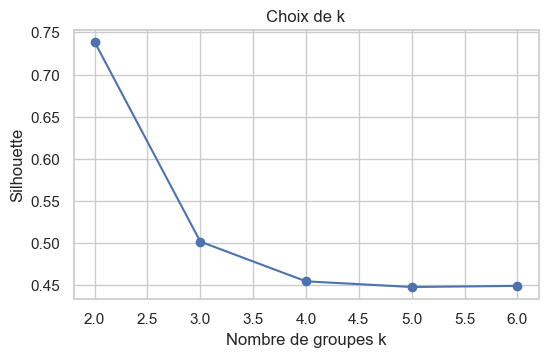

k retenu : 2 | silhouette = 0.739


In [ ]:
features_b = ["part_marche", "part_collectif", "part_taxi", "part_individuel",
              "duree_moy", "cout_moy", "part_intra"]

assembler_b = VectorAssembler(inputCols=features_b, outputCol="raw_features")
scaler = StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)
data_b = assembler_b.transform(profil.fillna(0, subset=features_b))
scaler_model = scaler.fit(data_b)
data_b = scaler_model.transform(data_b)

silhouette = ClusteringEvaluator(featuresCol="features")
scores = {}
for k in range(2, 7):
    m = KMeans(k=k, seed=42, featuresCol="features").fit(data_b)
    scores[k] = silhouette.evaluate(m.transform(data_b))

plt.figure(figsize=(6, 3.5))
plt.plot(list(scores.keys()), list(scores.values()), marker="o")
plt.xlabel("Nombre de groupes k")
plt.ylabel("Silhouette")
plt.title("Choix de k")
plt.show()

best_k = max(scores, key=scores.get)
print("k retenu :", best_k, "| silhouette =", round(scores[best_k], 3))

**Lecture.** Le coefficient de silhouette est maximal pour **k = 2** (silhouette = **0,739**). Il chute nettement à k = 3 (0,50), puis se stabilise autour de 0,45 pour k = 4 à 6.

**Pourquoi k = 2 et non 3 ?** La silhouette mesure, pour chaque strate, si elle est plus proche des strates de son groupe que de celles du groupe voisin (de -1 à 1). À k = 2, les deux groupes sont nettement séparés (0,74, au-delà du seuil de 0,5 qui signale une structure forte). Passer à 3 groupes fait perdre un tiers de cette qualité : le troisième groupe ne correspond pas à une frontière nette, il découpe artificiellement l'un des deux groupes existants. La carte ACP le confirme : les strates forment deux nuages bien distincts, et à l'intérieur du grand groupe on observe un **gradient continu** (des strates rurales aux quartiers proches du centre), sans rupture qui justifierait un troisième groupe.

## B.3 Profil des groupes

In [ ]:
kmeans = KMeans(k=best_k, seed=42, featuresCol="features").fit(data_b)
clusters = kmeans.transform(data_b).withColumnRenamed("prediction", "Groupe")

clusters.groupBy("Groupe").agg(
    F.count("*").alias("nb_strates"),
    *[F.round(F.avg(c), 2).alias(c) for c in features_b]
).orderBy("Groupe").show(truncate=False)

+------+----------+-----------+--------------+---------+---------------+---------+--------+----------+
|Groupe|nb_strates|part_marche|part_collectif|part_taxi|part_individuel|duree_moy|cout_moy|part_intra|
+------+----------+-----------+--------------+---------+---------------+---------+--------+----------+
|0     |33        |0.89       |0.17          |0.07     |0.03           |17.1     |62.12   |0.72      |
|1     |8         |0.7        |0.26          |0.13     |0.15           |24.96    |165.75  |0.47      |
+------+----------+-----------+--------------+---------+---------------+---------+--------+----------+



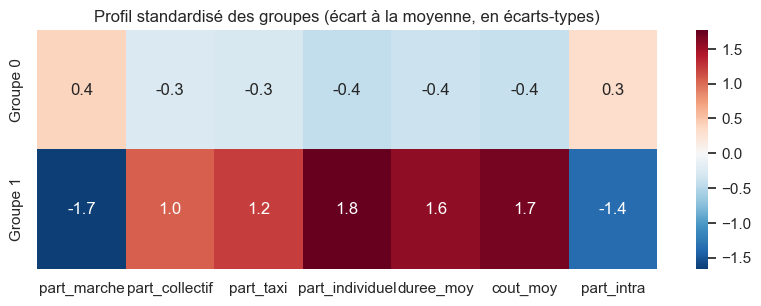

In [ ]:
centres = pd.DataFrame(kmeans.clusterCenters(), columns=features_b)
centres.index = [f"Groupe {i}" for i in range(best_k)]

plt.figure(figsize=(10, 0.8 * best_k + 1.5))
sns.heatmap(centres, annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Profil standardisé des groupes (écart à la moyenne, en écarts-types)")
plt.show()

In [ ]:
clusters.groupBy("Groupe").agg(
    F.concat_ws(", ", F.sort_array(F.collect_list(F.concat_ws(" - ", "Strate", "Commune")))).alias("Strates")
).orderBy("Groupe").show(truncate=False)

+------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|Groupe|Strates                                                                                                                                            

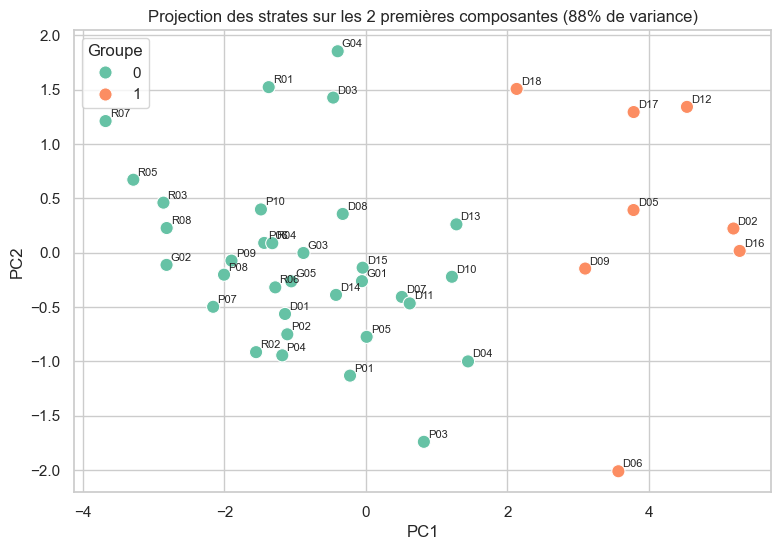

In [ ]:
pca = PCA(k=2, inputCol="features", outputCol="pca").fit(clusters)
proj = pca.transform(clusters).select("Strate", "Groupe", "pca").toPandas()
proj["PC1"] = proj.pca.apply(lambda v: v[0])
proj["PC2"] = proj.pca.apply(lambda v: v[1])

plt.figure(figsize=(9, 6))
sns.scatterplot(data=proj, x="PC1", y="PC2", hue="Groupe", palette="Set2", s=90)
for _, r in proj.iterrows():
    plt.annotate(r.Strate, (r.PC1, r.PC2), fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.title(f"Projection des strates sur les 2 premières composantes ({pca.explainedVariance.sum():.0%} de variance)")
plt.show()

**Interprétation des groupes.**

La carte de chaleur se lit en écarts à la moyenne : le rouge signale une valeur au-dessus de la moyenne des strates, le bleu une valeur en dessous. Elle oppose nettement deux types de territoires.

- **Groupe 1 — Quartiers centraux et motorisés (8 strates).** Mermoz-Sacré-Cœur, Dieuppeul-Derklé, Fann-Point E-Amitié, Hann Bel-Air, Ngor, Plateau, Sicap Liberté, Yoff. Ces strates présentent :
  - une part de marche plus faible (70 % contre 89 %) ;
  - un recours nettement plus fréquent aux modes individuels (15 % contre 3 %), au taxi (13 % contre 7 %) et au transport collectif (26 % contre 17 %) ;
  - des déplacements plus longs (25 min contre 17) et plus coûteux (166 FCFA contre 62) ;
  - moins de déplacements internes (47 % contre 72 %).

  Ce sont les quartiers du centre de Dakar, qui regroupent le centre des affaires (Plateau) et des quartiers résidentiels aisés. Leurs habitants se déplacent plus loin et plus souvent en mode motorisé.
- **Groupe 0 — Zones de mobilité de proximité (33 strates).** Ce groupe réunit les autres communes de Dakar ainsi que l'ensemble de Guédiawaye, de Pikine et de Rufisque. La mobilité y est **locale et essentiellement pédestre** : 89 % des déplacements comportent de la marche et 72 % restent dans la strate.

La projection en ACP (88 % de la variance sur deux axes) confirme cette opposition : le premier axe sépare clairement les deux groupes. Au sein du groupe 0, il fait aussi apparaître un gradient, des strates rurales et périurbaines les plus repliées sur elles-mêmes (Sendou-Yène, Bargny, Rufisque Nord) jusqu'aux quartiers dakarois plus proches du centre (Gueule Tapée, Ouakam, HLM).

---
# Synthèse : croisement des deux analyses

On rattache chaque déplacement au groupe de sa strate de départ, afin de mesurer le taux de déplacements payants par type de territoire.

In [ ]:
df_groupe = df.join(clusters.select(F.col("Strate").alias("Origine_StrateDepart"), "Groupe"), "Origine_StrateDepart")

taux_payant(df_groupe, "Groupe").show()
(df_groupe.groupBy("Groupe")
          .pivot("Sexe")
          .agg(F.round(F.sum(F.col("Poids_extra") * F.col("Payant")) / F.sum("Poids_extra") * 100, 1))
          .orderBy("Groupe").show())

+------+-----+-----------+
|Groupe|    n|taux_payant|
+------+-----+-----------+
|     0|37395|       21.3|
|     1| 7924|       35.8|
+------+-----+-----------+

+------+-----+-----+
|Groupe|Femme|Homme|
+------+-----+-----+
|     0| 21.9| 20.8|
|     1| 39.5| 33.1|
+------+-----+-----+



**Interprétation.** Le taux de déplacements payants atteint **35,8 %** dans les quartiers centraux (groupe 1), contre **21,3 %** dans les zones de proximité (groupe 0). La forte mobilité de proximité des quartiers périphériques limite donc le coût monétaire des déplacements. Elle peut toutefois traduire un accès plus restreint aux modes motorisés, que les données ne permettent pas de distinguer d'un choix.

Le léger excès de déplacements payants chez les femmes se concentre dans les quartiers centraux (39,5 % contre 33,1 % pour les hommes). Dans les zones de proximité, l'écart est quasi nul (21,9 % contre 20,8 %).

---
# Conclusion

Ce projet a mobilisé Spark à deux niveaux. Spark SQL a servi au nettoyage, à l'imputation, à la construction des variables et aux agrégations. MLlib a servi à la modélisation supervisée (régression logistique, forêt aléatoire, régression linéaire) et non supervisée (K-Means, ACP).

**Principaux résultats :**
1. **23,8 %** des déplacements de la région sont payants. Le recours à un mode payant est prévisible à partir du seul profil de l'individu et de la géographie du déplacement : avec un découpage par ménage, la forêt aléatoire obtient une **AUC de 0,879** et un **F1 de 0,69** sur la classe payante.
2. La **distance** en est de loin le premier déterminant : 61 % des déplacements entre strates sont payants, contre 6,5 % des déplacements internes. L'âge vient ensuite. Le sexe joue un rôle marginal.
3. Les **erreurs du modèle** s'expliquent : courts trajets payants en transport informel (faux négatifs) et trajets longs gratuits à pied ou en véhicule particulier (faux positifs).
4. Le **montant** payé dépend surtout du **mode** choisi. Sans le mode, le R² de la régression du coût ne dépasse pas 0,20 ; avec le mode, il atteint 0,78, le taxi coûtant plus de dix fois plus cher qu'un car rapide.
5. Les strates se répartissent en **deux types de territoires** (silhouette = 0,74) : les quartiers centraux de Dakar, motorisés, aux déplacements plus longs et plus coûteux, et une vaste périphérie à la mobilité de proximité, essentiellement pédestre.

**Limites :**
- L'absence de variable de revenu et de possession d'un véhicule empêche de distinguer marche choisie et marche contrainte, et explique une partie des faux positifs.
- La distance réelle n'est pas disponible ; `MemeStrate` et la durée n'en sont que des approximations.
- Le faible nombre de strates (41) limite la finesse du clustering.
- Les données décrivent une seule journée par individu.

**Perspectives :** intégrer le revenu, l'équipement en véhicules et des coordonnées géographiques, et appliquer le même pipeline à une enquête plus récente pour évaluer l'effet du BRT et du TER sur la mobilité.

In [ ]:
spark.stop()